# Unit 05 · k-d Trees for Nearest Neighbors

Brute-force nearest neighbor checks every point: O(n) per query. Earlier we sorted by x and used a 1D gap as a **lower bound** on the 2D distance to prune. A **k-d tree** applies that same idea on *both* axes at once.

In this notebook we build a 2D k-d tree from scratch and use it to find the **nearest neighbor** (k=1) of a query point.

**Plan:** build the tree, look at the splits, query it, count the work saved, then connect it to decision trees.

In [1]:
import math, random
import matplotlib.pyplot as plt

## Step 1: Build the tree

Recursively:
1. Pick the axis: x at depth 0, y at depth 1, x at depth 2, ... (`depth % 2`).
2. Sort the points on that axis and take the **median** as the node.
3. Points below the median go left, points above go right. Repeat on each half.

Every point ends up as exactly one node, and the tree is balanced because we always split at the median.

In [9]:
numPoints = 100

class Node:
    def __init__(self, point, axis, left, right):
        self.point, self.axis, self.left, self.right = point, axis, left, right

def build(points, depth=0):
    if not points:
        return None
    axis = depth % 2                        # alternate x, y, x, y, ...
    pts = sorted(points, key=lambda p: p[axis])
    mid = len(pts) // 2                     # median
    return Node(pts[mid], axis,
                build(pts[:mid], depth + 1),
                build(pts[mid + 1:], depth + 1))

random.seed(1)
small = [
    (round(random.uniform(0, 10), 1), round(random.uniform(0, 10), 1))
    for _ in range(numPoints)
]
tree = build(small)

def show(node, depth=0):
    if node is None:
        return
    print("    " * depth + f"{node.point}  splits on {'xy'[node.axis]}")
    show(node.left, depth + 1)
    show(node.right, depth + 1)

show(tree)

(5.0, 4.5)  splits on x
    (4.4, 5.0)  splits on y
        (2.3, 2.3)  splits on x
            (1.7, 2.7)  splits on y
                (0.3, 2.3)  splits on x
                    (0.2, 0.2)  splits on y
                        (0.2, 0.1)  splits on x
                        (0.3, 2.2)  splits on x
                    (0.3, 2.4)  splits on y
                        (0.9, 0.3)  splits on x
                (1.2, 3.3)  splits on x
                    (0.2, 3.9)  splits on y
                        (0.6, 3.0)  splits on x
                    (2.2, 4.6)  splits on y
                        (2.2, 4.2)  splits on x
            (4.3, 1.9)  splits on y
                (3.9, 1.7)  splits on x
                    (2.9, 0.2)  splits on y
                        (2.5, 0.1)  splits on x
                        (3.4, 0.7)  splits on x
                    (4.2, 1.9)  splits on y
                        (4.9, 0.3)  splits on x
                (3.6, 3.5)  splits on x
                    (3.0, 5.0)  spli

## Step 2: Draw the splits

Each node is a line that cuts its region in two: a vertical line for an x-split, a horizontal one for a y-split. The picture is the tree.

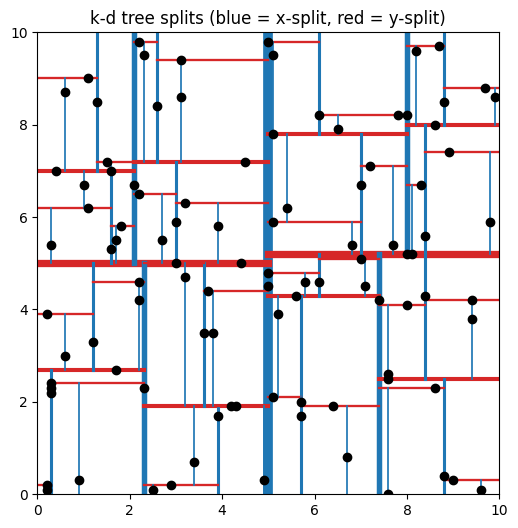

In [19]:
def draw_splits(node, xmin, xmax, ymin, ymax, ax, lw):
    scale = 0.75
    if node is None:
        return
    x, y = node.point
    if node.axis == 0:                      # vertical line, limited to this region
        ax.plot([x, x], [ymin, ymax], color="tab:blue", lw=lw)
        draw_splits(node.left,  xmin, x, ymin, ymax, ax, lw * scale)
        draw_splits(node.right, x, xmax, ymin, ymax, ax, lw * scale)
    else:                                   # horizontal line, limited to this region
        ax.plot([xmin, xmax], [y, y], color="tab:red", lw=lw)
        draw_splits(node.left, xmin, xmax, ymin, y, ax, lw * scale)
        draw_splits(node.right, xmin, xmax, y, ymax, ax, lw * scale)

fig, ax = plt.subplots(figsize=(6, 6))
draw_splits(tree, 0, 10, 0, 10, ax, 7)
ax.scatter(*zip(*small), color="black", zorder=3)
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.set_aspect("equal")
ax.set_title("k-d tree splits (blue = x-split, red = y-split)")
plt.show()

## Step 3: Query for the nearest neighbor

The search is a binary search plus a **backtracking check**:

1. At each node, compare the query to the node's split value and go to the **near** side first (this is the "binary search" part).
2. On the way back up, ask: *could the far side hold a better point?* The far side is at least `|q[axis] - split|` away, since that is the gap to the splitting line. If that gap is already larger than our best distance so far, skip the far side entirely.

We only need to remember one thing: the best point so far and its distance. We also count how many nodes get visited.

In [11]:
def dist2(a, b):
    return (a[0] - b[0]) ** 2 + (a[1] - b[1]) ** 2

def nearest(root, q):
    best_point, best_d2 = None, float("inf")
    visited = 0

    def search(node):
        nonlocal best_point, best_d2, visited
        if node is None:
            return
        visited += 1

        d2 = dist2(node.point, q)
        if d2 < best_d2:
            best_point, best_d2 = node.point, d2

        diff = q[node.axis] - node.point[node.axis]
        near, far = (node.left, node.right) if diff < 0 else (node.right, node.left)

        search(near)
        # only cross the splitting line if the line is closer than our best so far
        if diff ** 2 < best_d2:
            search(far)

    search(root)
    return best_point, math.sqrt(best_d2), visited

q = (5.0, 5.0)
best, dist, visited = nearest(tree, q)
print("nearest to", q, ":", best, "at distance", round(dist, 3))
print("nodes visited:", visited, "of", len(small))

nearest to (5.0, 5.0) : (5.0, 4.8) at distance 0.2
nodes visited: 16 of 100


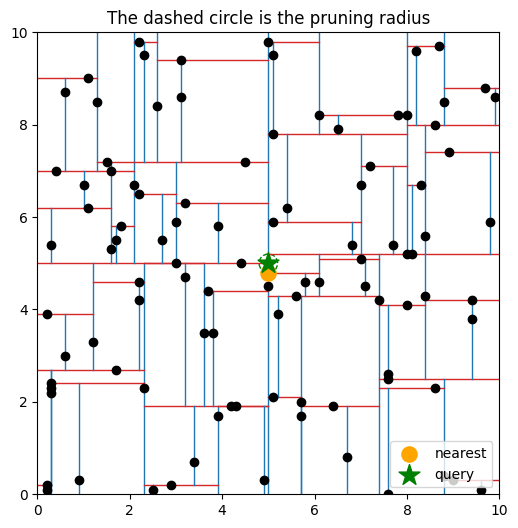

In [12]:
fig, ax = plt.subplots(figsize=(6, 6))
draw_splits(tree, 0, 10, 0, 10, ax)
ax.scatter(*zip(*small), color="black", zorder=3)
ax.scatter(*best, color="orange", s=120, zorder=4, label="nearest")
ax.scatter(*q, marker="*", color="green", s=250, zorder=5, label="query")
ax.add_patch(plt.Circle(q, dist, fill=False, ls="--", color="green"))
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.set_aspect("equal"); ax.legend()
ax.set_title("The dashed circle is the pruning radius")
plt.show()

The dashed circle is the distance to the nearest neighbor. A splitting line that does not cross the circle cannot hide a closer point on its far side, so the search never looks there.

## Step 4: Check against brute force, and count the savings

In [13]:
def brute(points, q):
    return min(points, key=lambda p: dist2(p, q))

random.seed(0)
n = 5000
points = list({(round(random.random(), 4), round(random.random(), 4)) for _ in range(n)})
big = build(points)

total_visited, trials = 0, 500
for _ in range(trials):
    q = (random.random(), random.random())
    got, _, v = nearest(big, q)
    want = brute(points, q)
    assert dist2(got, q) == dist2(want, q)     # compare distances in case of ties
    total_visited += v

print(f"all {trials} queries matched brute force")
print(f"average nodes visited: {total_visited / trials:.1f} out of {len(points)}")

all 500 queries matched brute force
average nodes visited: 17.8 out of 5000


**The case that broke the sorted-X idea.** All points on a vertical line meant no x-gap ever pruned anything. The k-d tree splits on y at the next level, so it still prunes. (The pruning only helps when the query is close to the data. A query far from the line has a large best distance, and then few splits can be skipped.)

In [14]:
line = [(0.0, i / 1000) for i in range(1000)]
line_tree = build(line)
_, _, v = nearest(line_tree, (0.0, 0.5))
print("nodes visited on the vertical line:", v, "of", len(line))
print("sorted-X pruning would visit all", len(line), "(every x-gap is 0)")

nodes visited on the vertical line: 10 of 1000
sorted-X pruning would visit all 1000 (every x-gap is 0)


## Step 5: Draw the tree itself

Same 15 points as Step 2, but now we draw the tree as a graph: an arrow from `u` to `v` whenever `u` is the parent of `v`. No partition lines this time.

The root is circled. Edges are colored by the **parent's** split axis (blue = parent splits on x, red = parent splits on y), so you can see the left/right choice: from a blue parent the child is to the left or right, from a red parent it is below or above.

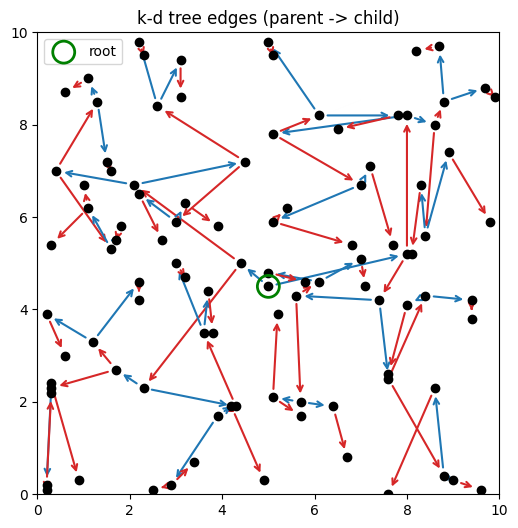

In [15]:
def draw_edges(node, ax):
    if node is None:
        return
    color = "tab:blue" if node.axis == 0 else "tab:red"
    for child in (node.left, node.right):
        if child is not None:
            ax.annotate("", xy=child.point, xytext=node.point,
                        arrowprops=dict(arrowstyle="->", color=color, lw=1.5,
                                        shrinkA=6, shrinkB=6))
            draw_edges(child, ax)

fig, ax = plt.subplots(figsize=(6, 6))
draw_edges(tree, ax)
ax.scatter(*zip(*small), color="black", zorder=3)
ax.scatter(*tree.point, s=250, facecolors="none", edgecolors="green", lw=2, zorder=4, label="root")
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.set_aspect("equal"); ax.legend()
ax.set_title("k-d tree edges (parent -> child)")
plt.show()

## Step 6: The decision tree connection

Next unit's decision trees look a lot like what we just built.

| | k-d tree | Decision tree |
|---|---|---|
| Structure | binary tree of axis-aligned splits | binary tree of axis-aligned splits |
| Each node asks | "is `x < 4.2`?" or "is `y < 7.1`?" | "is `feature_j < threshold`?" |
| Regions | rectangles that tile the plane | rectangles that tile the feature space |
| How the split is chosen | alternate axes, split at the **median** (ignores labels) | try axes and thresholds, pick the best by **impurity** (uses labels) |
| Goal | find where a point lives, then search nearby | predict a label from the leaf a point lands in |

So the splitting picture from Step 2 is also what a decision tree's decision regions look like. The k-d tree decides splits by geometry, to organize the points. A decision tree decides splits by labels, to separate the classes.

**Questions to think about**
1. A k-d tree splits at the median every time. What does that guarantee about the tree's depth? What would a decision tree lose or gain by doing the same?
2. In 50 dimensions, a point is split on a given axis only about once every 50 levels. Why does that hurt pruning?
3. In our search we used `diff ** 2 < best_d2`. What would go wrong if we used `<=` or dropped the check on the far side altogether?